# 🧹 Notebook 2: Làm Sạch Dữ liệu (Data Cleaning & Preprocessing)
## Đề tài: Phân tích và Dự đoán Khách hàng Rời bỏ (Customer Churn Prediction)

---

### Các vấn đề sẽ xử lý trong notebook này:

| # | Vấn đề | Cột liên quan | Loại | Phương pháp |
|---|---------|--------------|------|-------------|
| 1 | Cột không cần thiết | `customerID` | Irrelevant | Drop |
| 2 | Sai kiểu dữ liệu + Missing Values | `TotalCharges` | **MAR** | Convert + Imputation |
| 3 | Sai kiểu dữ liệu | `SeniorCitizen` | Type error | Map 0→No, 1→Yes |
| 4 | Giá trị dư thừa/không nhất quán | 7 cột dịch vụ | Encoding issue | Replace → 'No' |
| 5 | Encode biến mục tiêu | `Churn` | Target encode | Map Yes→1, No→0 |
| 6 | Label Encoding | Biến binary | Categorical | LabelEncoder |
| 7 | One-Hot Encoding | Biến đa giá trị | Categorical | get_dummies |
| 8 | Feature Scaling | Biến số | Numeric | StandardScaler |
| 9 | Class Imbalance | `Churn` | Target imbalance | class_weight |

In [1]:
# ============================================================
# IMPORT THƯ VIỆN
# ============================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.impute import SimpleImputer

warnings.filterwarnings('ignore')
plt.rcParams['figure.dpi'] = 120
sns.set_style('whitegrid')

print('✅ Import thư viện thành công!')

✅ Import thư viện thành công!


In [2]:
# ============================================================
# TẢI DỮ LIỆU GỐC
# ============================================================
    data_path = '../data/raw/telco_churn.csv' if os.path.exists('../data/raw/telco_churn.csv') else 'data/raw/telco_churn.csv'
    df_raw = pd.read_csv(data_path)
df = df_raw.copy()  # Luôn làm việc trên bản copy, giữ raw data nguyên

print(f'✅ Tải dữ liệu gốc: {df.shape[0]:,} hàng × {df.shape[1]} cột')
print(f'   TotalCharges dtype: {df["TotalCharges"].dtype}  ← Đây là string!')

✅ Tải dữ liệu gốc: 7,043 hàng × 21 cột
   TotalCharges dtype: str  ← Đây là string!


---
## Bước 1: Xóa Cột `customerID` (Không có giá trị dự đoán)

**Lý do:** `customerID` là mã định danh duy nhất của từng khách hàng. Nó không chứa bất kỳ thông tin nào có thể giúp mô hình học hay dự đoán. Giữ lại sẽ gây **data leakage** ngầm định và tăng chiều dữ liệu vô ích.

In [3]:
# ============================================================
# BƯỚC 1: DROP customerID
# ============================================================
print('TRƯỚC khi drop:')
print(f'  Số cột: {df.shape[1]}')
print(f'  Cột customerID: {df["customerID"].nunique()} giá trị unique (unique hoàn toàn → không có giá trị dự đoán)')

df.drop('customerID', axis=1, inplace=True)

print('\nSAU khi drop:')
print(f'  Số cột: {df.shape[1]}')
print('  ✅ Đã xóa cột customerID')

TRƯỚC khi drop:
  Số cột: 21
  Cột customerID: 7043 giá trị unique (unique hoàn toàn → không có giá trị dự đoán)

SAU khi drop:
  Số cột: 20
  ✅ Đã xóa cột customerID


---
## Bước 2: Xử lý Cột `TotalCharges` – Vấn đề Nghiêm trọng Nhất

### 🔍 Phân tích chi tiết

**Vấn đề 1: Sai kiểu dữ liệu**  
Cột `TotalCharges` trong file CSV được lưu dạng **`object` (string)** thay vì `float`. Nguyên nhân do một số ô chứa **khoảng trắng `" "`** — đây là giá trị rỗng được nhập sai trong nguồn dữ liệu.

**Vấn đề 2: Missing Values (Giá trị Thiếu)**  
Sau khi convert sang numeric, 11 ô khoảng trắng trở thành `NaN`.

### 📊 Loại Missing Data: **MAR (Missing At Random)**

| Tiêu chí kiểm tra | Kết quả |
|---|---|
| Tỉ lệ missing | 11/7043 ≈ **0.15%** |
| Có pattern không? | ✅ **Có** — tất cả đều có `tenure = 0` |
| Phụ thuộc biến có thể quan sát? | ✅ **Phụ thuộc `tenure`** |
| Phụ thuộc chính giá trị bị thiếu? | ❌ Không |

**→ Kết luận: MAR**  
- Không phải **MCAR**: vì không ngẫu nhiên hoàn toàn (có liên hệ với `tenure = 0`)  
- Không phải **MNAR**: vì không phải bản thân giá trị `TotalCharges` quyết định nó bị thiếu  
- Là **MAR**: missing phụ thuộc vào `tenure` — biến có thể quan sát được trong dataset

### ✅ Phương pháp xử lý: Imputation (Điền giá trị thay thế)
**Tại sao không Drop?** Chỉ có 11 hàng (0.15%) — drop gây mất thông tin không đáng. Nhóm `tenure=0` là nhóm khách hàng **mới** — quan trọng cho phân tích churn sớm.

In [4]:
# ============================================================
# BƯỚC 2A: CHUYỂN ĐỔI KIỂU DỮ LIỆU TotalCharges
# ============================================================
print('--- TRƯỚC KHI XỬ LÝ ---')
print(f'Dtype TotalCharges: {df["TotalCharges"].dtype}')
print(f'NaN trực tiếp: {df["TotalCharges"].isnull().sum()}')

# Bước 1: Xác định các hàng có khoảng trắng
blank_mask = df['TotalCharges'].str.strip() == ''
print(f'Số hàng chứa khoảng trắng " ": {blank_mask.sum()}')

# Bước 2: Convert sang numeric (khoảng trắng → NaN)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

print(f'\n--- SAU KHI CONVERT ---')
print(f'Dtype TotalCharges: {df["TotalCharges"].dtype}  ✅')
print(f'NaN sau convert: {df["TotalCharges"].isnull().sum()}')
print()

# Hiển thị các hàng bị NaN
print('Các hàng có TotalCharges = NaN:')
nan_rows = df[df['TotalCharges'].isnull()]
print(nan_rows[['tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']].to_string())

--- TRƯỚC KHI XỬ LÝ ---
Dtype TotalCharges: str
NaN trực tiếp: 0
Số hàng chứa khoảng trắng " ": 11

--- SAU KHI CONVERT ---
Dtype TotalCharges: float64  ✅
NaN sau convert: 11

Các hàng có TotalCharges = NaN:
      tenure  MonthlyCharges  TotalCharges Churn
488        0           52.55           NaN    No
753        0           20.25           NaN    No
936        0           80.85           NaN    No
1082       0           25.75           NaN    No
1340       0           56.05           NaN    No
3331       0           19.85           NaN    No
3826       0           25.35           NaN    No
4380       0           20.00           NaN    No
5218       0           19.70           NaN    No
6670       0           73.35           NaN    No
6754       0           61.90           NaN    No


In [5]:
# ============================================================
# BƯỚC 2B: IMPUTATION – ĐIỀN GIÁ TRỊ THIẾU
# ============================================================
print('--- PHƯƠNG PHÁP IMPUTATION ---')
print()
print('Logic: TotalCharges = MonthlyCharges × tenure')
print('  Khi tenure = 0: TotalCharges hợp lý nhất = MonthlyCharges (phí tháng đầu)')
print('  Hoặc = 0 nếu khách hàng chưa thanh toán.')
print('  → Chọn fill bằng MonthlyCharges (bảo thủ, hợp lý về business)')
print()

# PHƯƠNG PHÁP CHỌN: Fill bằng MonthlyCharges
df['TotalCharges'] = df['TotalCharges'].fillna(df['MonthlyCharges'])

print(f'✅ Sau imputation: NaN còn lại = {df["TotalCharges"].isnull().sum()}')
print()
print('--- KIỂM TRA KẾT QUẢ ---')
print(df.iloc[nan_rows.index][['tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']])

--- PHƯƠNG PHÁP IMPUTATION ---

Logic: TotalCharges = MonthlyCharges × tenure
  Khi tenure = 0: TotalCharges hợp lý nhất = MonthlyCharges (phí tháng đầu)
  Hoặc = 0 nếu khách hàng chưa thanh toán.
  → Chọn fill bằng MonthlyCharges (bảo thủ, hợp lý về business)

✅ Sau imputation: NaN còn lại = 0

--- KIỂM TRA KẾT QUẢ ---
      tenure  MonthlyCharges  TotalCharges Churn
488        0           52.55         52.55    No
753        0           20.25         20.25    No
936        0           80.85         80.85    No
1082       0           25.75         25.75    No
1340       0           56.05         56.05    No
3331       0           19.85         19.85    No
3826       0           25.35         25.35    No
4380       0           20.00         20.00    No
5218       0           19.70         19.70    No
6670       0           73.35         73.35    No
6754       0           61.90         61.90    No


---
## Bước 3: Xử lý Cột `SeniorCitizen` – Sai Kiểu Dữ liệu

**Vấn đề:** Cột được lưu là số nguyên `0/1` nhưng thực chất là biến **phân loại nhị phân** (Yes/No).  
**Tại sao cần xử lý?** Nếu giữ nguyên `0/1`, một số mô hình có thể hiểu nhầm đây là biến liên tục có thứ tự (ordinal), dẫn đến bias không cần thiết. Việc convert sang `Yes/No` giúp xử lý nhất quán với các biến categorical khác.

In [6]:
# ============================================================
# BƯỚC 3: XỬ LÝ SeniorCitizen
# ============================================================
print(f'TRƯỚC: SeniorCitizen dtype = {df["SeniorCitizen"].dtype}')
print(f'  Giá trị unique: {df["SeniorCitizen"].unique()}')
print(f'  Phân bố: {dict(df["SeniorCitizen"].value_counts())}')

df['SeniorCitizen'] = df['SeniorCitizen'].map({0: 'No', 1: 'Yes'})

print(f'\nSAU: SeniorCitizen dtype = {df["SeniorCitizen"].dtype}')
print(f'  Giá trị unique: {df["SeniorCitizen"].unique()}')
print('✅ Đã convert SeniorCitizen sang Yes/No')

TRƯỚC: SeniorCitizen dtype = int64
  Giá trị unique: [0 1]
  Phân bố: {0: np.int64(5901), 1: np.int64(1142)}

SAU: SeniorCitizen dtype = str
  Giá trị unique: <StringArray>
['No', 'Yes']
Length: 2, dtype: str
✅ Đã convert SeniorCitizen sang Yes/No


---
## Bước 4: Chuẩn hóa Giá trị "No internet service" và "No phone service"

**Vấn đề:** 7 cột dịch vụ có giá trị `"No internet service"` / `"No phone service"` về mặt ngữ nghĩa **tương đương với `"No"`**. Đây là dư thừa trong encoding.

**Tại sao cần chuẩn hóa?** Giữ nguyên sẽ tạo ra nhiều categories không cần thiết khi One-Hot Encoding, tăng chiều dữ liệu và có thể gây multicollinearity.

In [7]:
# ============================================================
# BƯỚC 4: CHUẨN HÓA GIÁ TRỊ DƯ THỪA
# ============================================================
cols_to_clean = [
    'MultipleLines',    # có "No phone service"
    'OnlineSecurity',   # có "No internet service"
    'OnlineBackup',     # có "No internet service"
    'DeviceProtection', # có "No internet service"
    'TechSupport',      # có "No internet service"
    'StreamingTV',      # có "No internet service"
    'StreamingMovies',  # có "No internet service"
]

print('TRƯỚC khi chuẩn hóa:')
for col in cols_to_clean:
    print(f'  {col}: {sorted(df[col].unique())}')

for col in cols_to_clean:
    df[col] = df[col].replace({
        'No internet service': 'No',
        'No phone service': 'No'
    })

print('\nSAU khi chuẩn hóa:')
for col in cols_to_clean:
    print(f'  {col}: {sorted(df[col].unique())}')
    
print('\n✅ Đã chuẩn hóa 7 cột dịch vụ về 2 giá trị: [No, Yes]')

TRƯỚC khi chuẩn hóa:
  MultipleLines: ['No', 'No phone service', 'Yes']
  OnlineSecurity: ['No', 'No internet service', 'Yes']
  OnlineBackup: ['No', 'No internet service', 'Yes']
  DeviceProtection: ['No', 'No internet service', 'Yes']
  TechSupport: ['No', 'No internet service', 'Yes']
  StreamingTV: ['No', 'No internet service', 'Yes']
  StreamingMovies: ['No', 'No internet service', 'Yes']

SAU khi chuẩn hóa:
  MultipleLines: ['No', 'Yes']
  OnlineSecurity: ['No', 'Yes']
  OnlineBackup: ['No', 'Yes']
  DeviceProtection: ['No', 'Yes']
  TechSupport: ['No', 'Yes']
  StreamingTV: ['No', 'Yes']
  StreamingMovies: ['No', 'Yes']

✅ Đã chuẩn hóa 7 cột dịch vụ về 2 giá trị: [No, Yes]


---
## Bước 5: Encode Biến Mục tiêu `Churn`

**Tại sao?** Mô hình ML cần nhận đầu vào là số. `Yes → 1` (Churn), `No → 0` (Không Churn).

In [8]:
# ============================================================
# BƯỚC 5: ENCODE TARGET VARIABLE
# ============================================================
print(f'TRƯỚC: Churn values = {df["Churn"].unique()}')

df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

print(f'SAU: Churn values = {df["Churn"].unique()}')
print(f'\nPhân bố target:')
churn_dist = df['Churn'].value_counts()
for label, count in churn_dist.items():
    pct = count / len(df) * 100
    class_name = 'Churn (Yes=1)' if label == 1 else 'No Churn (No=0)'
    print(f'  {class_name}: {count:,} ({pct:.1f}%)')

print(f'\n⚠️  Tỉ lệ imbalance: {churn_dist[0]/churn_dist[1]:.2f}:1')
print('   → Cần xử lý khi train model bằng class_weight="balanced"')

TRƯỚC: Churn values = <StringArray>
['No', 'Yes']
Length: 2, dtype: str
SAU: Churn values = [0 1]

Phân bố target:
  No Churn (No=0): 5,174 (73.5%)
  Churn (Yes=1): 1,869 (26.5%)

⚠️  Tỉ lệ imbalance: 2.77:1
   → Cần xử lý khi train model bằng class_weight="balanced"


---
## Bước 6: Kiểm tra Tổng thể sau Data Cleaning

In [9]:
# ============================================================
# KIỂM TRA TỔNG THỂ SAU DATA CLEANING
# ============================================================
print('=' * 60)
print('  KIỂM TRA TỔNG THỂ SAU DATA CLEANING')
print('=' * 60)
print(f'Số hàng: {df.shape[0]:,}')
print(f'Số cột: {df.shape[1]}')
print(f'NaN còn lại: {df.isnull().sum().sum()}')
print()
print('Kiểu dữ liệu các cột:')
print(df.dtypes.to_string())

  KIỂM TRA TỔNG THỂ SAU DATA CLEANING
Số hàng: 7,043
Số cột: 20
NaN còn lại: 0

Kiểu dữ liệu các cột:
gender                  str
SeniorCitizen           str
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
Churn                 int64


---
## Bước 7: Feature Engineering & Encoding

Chuẩn bị dữ liệu để đưa vào mô hình ML.

In [10]:
# ============================================================
# BƯỚC 7A: TẠO FEATURE MỚI (Feature Engineering)
# ============================================================
print('--- TẠO FEATURE MỚI ---')

# Feature 1: Phí trung bình mỗi tháng thực tế
# Tránh chia cho 0 khi tenure = 0 bằng cách cộng thêm 1
df['AvgChargePerMonth'] = df['TotalCharges'] / (df['tenure'] + 1)
print('✅ Tạo feature: AvgChargePerMonth = TotalCharges / (tenure + 1)')

# Feature 2: Số lượng dịch vụ đang dùng
service_cols = ['PhoneService', 'MultipleLines', 'OnlineSecurity', 
                'OnlineBackup', 'DeviceProtection', 'TechSupport',
                'StreamingTV', 'StreamingMovies']
df['NumServices'] = df[service_cols].eq('Yes').sum(axis=1)
print('✅ Tạo feature: NumServices = tổng số dịch vụ đang dùng')

print(f'\nNhìn lại 5 hàng đầu với features mới:')
df[['tenure', 'MonthlyCharges', 'TotalCharges', 'AvgChargePerMonth', 'NumServices', 'Churn']].head()

--- TẠO FEATURE MỚI ---
✅ Tạo feature: AvgChargePerMonth = TotalCharges / (tenure + 1)
✅ Tạo feature: NumServices = tổng số dịch vụ đang dùng

Nhìn lại 5 hàng đầu với features mới:


In [11]:
# ============================================================
# BƯỚC 7B: ENCODING BIẾN CATEGORICAL
# ============================================================
print('--- ENCODING ---')

# Biến binary (Yes/No) → Label Encoding (0/1)
binary_cols = ['gender', 'Partner', 'Dependents', 'PhoneService', 
               'PaperlessBilling', 'MultipleLines', 'OnlineSecurity', 
               'OnlineBackup', 'DeviceProtection', 'TechSupport',
               'StreamingTV', 'StreamingMovies', 'SeniorCitizen']

le = LabelEncoder()
for col in binary_cols:
    df[col] = le.fit_transform(df[col])
    
print(f'✅ Label Encoding hoàn tất cho {len(binary_cols)} cột binary')
print(f'   Mapping: Female/No → 0, Male/Yes → 1 (LabelEncoder tự sắp xếp theo alphabet)')

# Biến đa giá trị → One-Hot Encoding
multi_cols = ['InternetService', 'Contract', 'PaymentMethod']
df = pd.get_dummies(df, columns=multi_cols, drop_first=True)

print(f'\n✅ One-Hot Encoding hoàn tất cho: {multi_cols}')
print(f'   Tổng số cột sau encoding: {df.shape[1]}')

# Convert boolean sang int
bool_cols = df.select_dtypes(include='bool').columns
df[bool_cols] = df[bool_cols].astype(int)
print(f'\n✅ Convert {len(bool_cols)} cột boolean sang int')

--- ENCODING ---
✅ Label Encoding hoàn tất cho 13 cột binary
   Mapping: Female/No → 0, Male/Yes → 1 (LabelEncoder tự sắp xếp theo alphabet)

✅ One-Hot Encoding hoàn tất cho: ['InternetService', 'Contract', 'PaymentMethod']
   Tổng số cột sau encoding: 26

✅ Convert 7 cột boolean sang int


In [12]:
# ============================================================
# BƯỚC 7C: FEATURE SCALING
# ============================================================
print('--- FEATURE SCALING (StandardScaler) ---')
print('Lý do dùng StandardScaler:')
print('  - Logistic Regression rất nhạy với scale của features')
print('  - tenure (0-72), MonthlyCharges (18-118), TotalCharges (18-8684) → chênh lệch lớn')
print('  - StandardScaler: μ=0, σ=1 → các features đồng nhất về scale')
print()

numeric_cols_to_scale = ['tenure', 'MonthlyCharges', 'TotalCharges', 
                         'AvgChargePerMonth', 'NumServices']

scaler = StandardScaler()
df[numeric_cols_to_scale] = scaler.fit_transform(df[numeric_cols_to_scale])

print(f'✅ Scaling hoàn tất cho: {numeric_cols_to_scale}')
print(f'\nKiểm tra sau scaling (mean ≈ 0, std ≈ 1):')
print(df[numeric_cols_to_scale].describe().loc[['mean', 'std']].round(4))

--- FEATURE SCALING (StandardScaler) ---
Lý do dùng StandardScaler:
  - Logistic Regression rất nhạy với scale của features
  - tenure (0-72), MonthlyCharges (18-118), TotalCharges (18-8684) → chênh lệch lớn
  - StandardScaler: μ=0, σ=1 → các features đồng nhất về scale

✅ Scaling hoàn tất cho: ['tenure', 'MonthlyCharges', 'TotalCharges', 'AvgChargePerMonth', 'NumServices']

Kiểm tra sau scaling (mean ≈ 0, std ≈ 1):
      tenure  MonthlyCharges  TotalCharges  AvgChargePerMonth  NumServices
mean -0.0000         -0.0000       -0.0000             0.0000      -0.0000
std   1.0001          1.0001        1.0001             1.0001       1.0001


In [13]:
# ============================================================
# TỔNG KẾT VÀ LƯU DỮ LIỆU ĐÃ CLEAN
# ============================================================
print('=' * 60)
print('  DỮ LIỆU SAU KHI CLEAN VÀ ENCODE')
print('=' * 60)
print(f'Số hàng: {df.shape[0]:,}')
print(f'Số cột: {df.shape[1]}')
print(f'NaN còn lại: {df.isnull().sum().sum()}')
print(f'Kiểu dữ liệu: {dict(df.dtypes.value_counts())}')
print()
print('Danh sách cột sau xử lý:')
for i, col in enumerate(df.columns, 1):
    print(f'  {i:2d}. {col}')

# Lưu file
    out_path = '../data/processed/telco_cleaned.csv' if os.path.exists('../data/processed') else 'data/processed/telco_cleaned.csv'
    df.to_csv(out_path, index=False)
print()
print('✅ Đã lưu: telco_churn_cleaned.csv')
print('✅ Sẵn sàng chuyển sang Notebook 3: Modeling!')

  DỮ LIỆU SAU KHI CLEAN VÀ ENCODE
Số hàng: 7,043
Số cột: 26
NaN còn lại: 0
Kiểu dữ liệu: {dtype('int64'): np.int64(21), dtype('float64'): np.int64(5)}

Danh sách cột sau xử lý:
   1. gender
   2. SeniorCitizen
   3. Partner
   4. Dependents
   5. tenure
   6. PhoneService
   7. MultipleLines
   8. OnlineSecurity
   9. OnlineBackup
  10. DeviceProtection
  11. TechSupport
  12. StreamingTV
  13. StreamingMovies
  14. PaperlessBilling
  15. MonthlyCharges
  16. TotalCharges
  17. Churn
  18. AvgChargePerMonth
  19. NumServices
  20. InternetService_Fiber optic
  21. InternetService_No
  22. Contract_One year
  23. Contract_Two year
  24. PaymentMethod_Credit card (automatic)
  25. PaymentMethod_Electronic check
  26. PaymentMethod_Mailed check

✅ Đã lưu: telco_churn_cleaned.csv
✅ Sẵn sàng chuyển sang Notebook 3: Modeling!


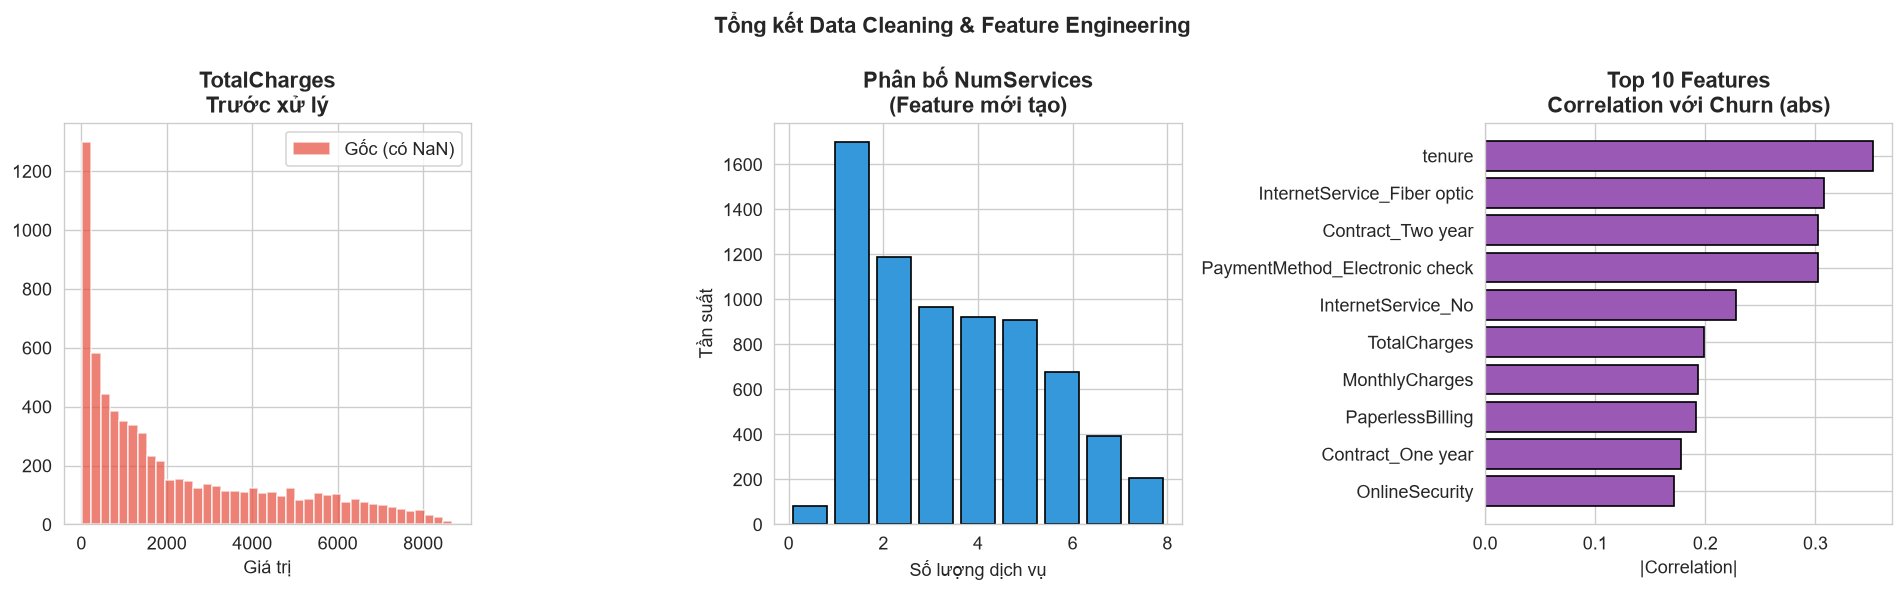

In [14]:
# ============================================================
# VISUALIZATION: SO SÁNH TRƯỚC & SAU CLEAN
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# TotalCharges distribution (trước và sau)
raw_tc = pd.to_numeric(df_raw['TotalCharges'], errors='coerce')

axes[0].hist(raw_tc.dropna(), bins=40, color='#e74c3c', alpha=0.7, label='Gốc (có NaN)')
axes[0].set_title('TotalCharges\nTrước xử lý', fontweight='bold')
axes[0].set_xlabel('Giá trị')
axes[0].legend()

# NumServices distribution
df['NumServices_unscaled'] = df_raw[service_cols].eq('Yes').sum(axis=1) 
axes[1].hist(df['NumServices_unscaled'], bins=9, color='#3498db', edgecolor='black', rwidth=0.8)
axes[1].set_title('Phân bố NumServices\n(Feature mới tạo)', fontweight='bold')
axes[1].set_xlabel('Số lượng dịch vụ')
axes[1].set_ylabel('Tần suất')
df.drop('NumServices_unscaled', axis=1, inplace=True)

# Correlation với Churn sau encoding
corr_churn = df.corr()['Churn'].drop('Churn').abs().sort_values(ascending=False).head(10)
axes[2].barh(corr_churn.index[::-1], corr_churn.values[::-1], color='#9b59b6', edgecolor='black')
axes[2].set_title('Top 10 Features\nCorrelation với Churn (abs)', fontweight='bold')
axes[2].set_xlabel('|Correlation|')

plt.suptitle('Tổng kết Data Cleaning & Feature Engineering', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('../reports/figures/07_cleaning_summary.png', bbox_inches='tight', dpi=150)
plt.show()